In [23]:
import copy, random, time
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.optim as optim
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, models, transforms as T
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

SEED = 42
def seed_everything(s=SEED):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True

seed_everything()
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [24]:
d1 = datasets.OxfordIIITPet("./data", split="trainval", download=True)
d2 = datasets.OxfordIIITPet("./data", split="test", download=True)

paths = d1._images + d2._images
labels = np.array(d1._labels + d2._labels)

#10 kelas pertama
keep = np.where(labels < 10)[0]
paths, labels = [paths[i] for i in keep], labels[keep]
print(f"Total data 10 kelas: {len(paths)}")

#70% train, 15% val, 15% test
idx = np.arange(len(paths))
tr, rest = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
va, te = train_test_split(rest, test_size=0.50, stratify=labels[rest], random_state=SEED)

class PetDataset(Dataset):
    def __init__(self, idxs, tf):
        self.idxs = idxs
        self.tf = tf
    def __len__(self):
        return len(self.idxs)
    def __getitem__(self, i):
        j = self.idxs[i]
        img = Image.open(paths[j]).convert("RGB")
        return self.tf(img), int(labels[j])

#Normalisasi ImageNet
norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
eval_tf = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(), norm])
aug_tf = T.Compose([
    T.Resize(256),
    T.RandomResizedCrop(224, scale=(0.8, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(), norm
])

val_loader = DataLoader(PetDataset(va, eval_tf), batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(PetDataset(te, eval_tf), batch_size=32, shuffle=False, num_workers=2)
print(f"Train: {len(tr)} | Val: {len(va)} | Test: {len(te)}")

Total data 10 kelas: 1981
Train: 1386 | Val: 297 | Test: 298


In [25]:
def build_model(mode):
    if mode == "scratch":
        m = models.resnet18(weights=None)
    else:
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        for p in m.parameters():
            p.requires_grad = False

    m.fc = nn.Linear(512, 10)

    if mode == "scratch":
        groups = [{'params': m.parameters(), 'lr': 1e-3}]
    else:
        groups = [{'params': m.fc.parameters(), 'lr': 1e-3}]
        if mode == "ft":
            for p in m.layer4.parameters():
                p.requires_grad = True
            groups.append({'params': m.layer4.parameters(), 'lr': 1e-4})

    return m.to(device), groups

def set_train_mode(model):
    model.train()
    for mod in model.modules():
        if isinstance(mod, nn.BatchNorm2d) and not mod.weight.requires_grad:
            mod.eval()

@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    total_loss = 0.0
    preds, targets = [], []
    for x, y in dl:
        out = model(x.to(device))
        loss = nn.functional.cross_entropy(out, y.to(device), reduction="sum")
        total_loss += loss.item()
        preds.extend(out.argmax(1).cpu().tolist())
        targets.extend(y.tolist())
    preds, targets = np.array(preds), np.array(targets)
    acc = (preds == targets).mean()
    f1 = f1_score(targets, preds, average="macro")
    return total_loss / len(targets), acc, f1

In [26]:
def run_experiment(code, mode, train_tf, max_epochs=30, patience=4):
    seed_everything()
    model, groups = build_model(mode)

    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\nRunning {code} | Trainable params: {trainable_params:,}")

    opt = optim.AdamW(groups, weight_decay=1e-2)
    train_loader = DataLoader(PetDataset(tr, train_tf), batch_size=32, shuffle=True, num_workers=2)

    best_val_loss = float('inf')
    best_epoch = 0
    wait_counter = 0
    history = []
    start_time = time.time()

    for ep in range(1, max_epochs + 1):
        set_train_mode(model)
        train_loss = 0.0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = nn.functional.cross_entropy(model(x), y)
            loss.backward()
            opt.step()
            train_loss += loss.item() * len(y)

        epoch_train_loss = train_loss / len(tr)
        val_loss, val_acc, _ = evaluate(model, val_loader)

        history.append({
            'code': code, 'epoch': ep,
            'train_loss': epoch_train_loss,
            'val_loss': val_loss, 'val_acc': val_acc
        })

        print(f"Epoch {ep:02d} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.3f}")


        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_epoch = ep
            wait_counter = 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait_counter += 1
            if wait_counter >= patience:
                print(f"Early stopping terpanggil di epoch {ep}!")
                break

    total_secs = time.time() - start_time
    model.load_state_dict(best_state)


    _, train_acc, _ = evaluate(model, DataLoader(PetDataset(tr, eval_tf), batch_size=32))
    _, val_acc_final, _ = evaluate(model, val_loader)
    test_acc, test_f1 = evaluate(model, test_loader)[1:]

    lr_str = ", ".join(f"{g['lr']:g}" for g in groups)
    row = {
        'code': code,
        'trainable_params': trainable_params,
        'lr': lr_str,
        'best_epoch': best_epoch,
        'duration_sec': round(total_secs, 1),
        'train_acc': round(train_acc, 4),
        'val_acc': round(val_acc_final, 4),
        'overfitting_gap': round(train_acc - val_acc_final, 4),
        'test_acc': round(test_acc, 4),
        'test_macro_f1': round(test_f1, 4)
    }
    return row, pd.DataFrame(history), model

In [27]:
experiments = [
    ("B1", "scratch", aug_tf),
    ("B2", "fe", aug_tf),
    ("B3", "ft", aug_tf),
    ("B4_noaug", "ft", eval_tf)
]

all_rows, all_histories = [], []
for code, mode, tf in experiments:
    row, hist, m = run_experiment(code, mode, tf)
    if code == "B3":
        best_model = m
    all_rows.append(row)
    all_histories.append(hist)

summary_df = pd.DataFrame(all_rows)
print("\nSummary result experiment")
print(summary_df.to_string(index=False))

summary_df.to_csv("metrics_summary.csv", index=False)
pd.concat(all_histories).to_csv("history_per_epoch.csv", index=False)



Running B1 | Trainable params: 11,181,642
Epoch 01 | Train Loss: 2.3336 | Val Loss: 2.6296 | Val Acc: 0.222
Epoch 02 | Train Loss: 2.0450 | Val Loss: 2.3833 | Val Acc: 0.269
Epoch 03 | Train Loss: 1.9072 | Val Loss: 2.3976 | Val Acc: 0.310
Epoch 04 | Train Loss: 1.8392 | Val Loss: 2.1356 | Val Acc: 0.300
Epoch 05 | Train Loss: 1.7559 | Val Loss: 2.4505 | Val Acc: 0.330
Epoch 06 | Train Loss: 1.6846 | Val Loss: 1.9686 | Val Acc: 0.340
Epoch 07 | Train Loss: 1.6083 | Val Loss: 1.7472 | Val Acc: 0.367
Epoch 08 | Train Loss: 1.6022 | Val Loss: 1.7720 | Val Acc: 0.384
Epoch 09 | Train Loss: 1.4840 | Val Loss: 1.6100 | Val Acc: 0.434
Epoch 10 | Train Loss: 1.4695 | Val Loss: 1.7488 | Val Acc: 0.397
Epoch 11 | Train Loss: 1.4141 | Val Loss: 1.7153 | Val Acc: 0.444
Epoch 12 | Train Loss: 1.3957 | Val Loss: 1.5390 | Val Acc: 0.458
Epoch 13 | Train Loss: 1.3418 | Val Loss: 1.5635 | Val Acc: 0.471
Epoch 14 | Train Loss: 1.2994 | Val Loss: 1.6642 | Val Acc: 0.468
Epoch 15 | Train Loss: 1.2495 | V

In [28]:
from google.colab import files
files.download('metrics_summary.csv')
files.download('history_per_epoch.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

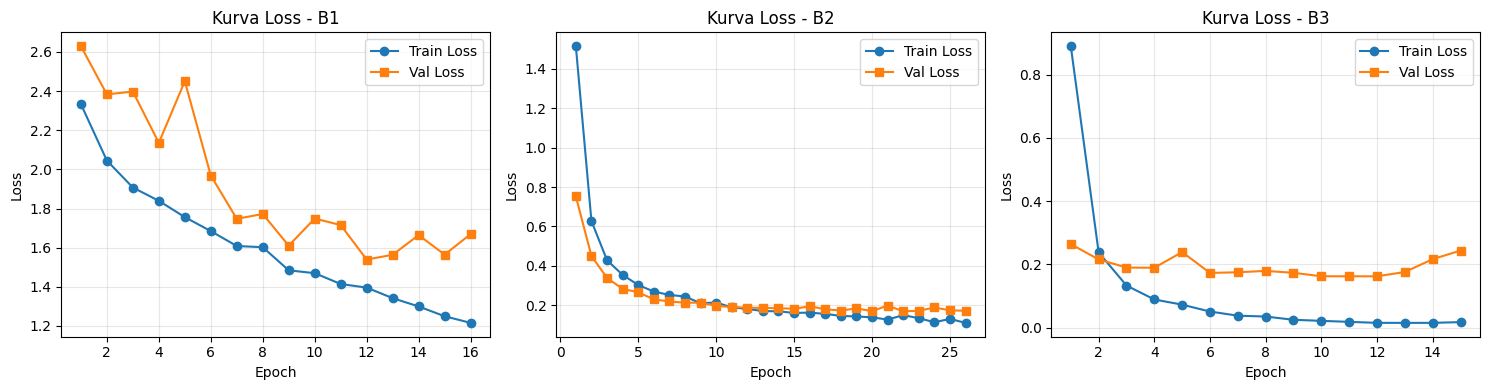

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

H = pd.read_csv("history_per_epoch.csv")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
codes = ["B1", "B2", "B3"]

for ax, c in zip(axes, codes):
    h = H[H.code == c]
    ax.plot(h.epoch, h.train_loss, "o-", label="Train Loss")
    ax.plot(h.epoch, h.val_loss, "s-", label="Val Loss")
    ax.set_title(f"Kurva Loss - {c}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig("curves.png", dpi=150)
plt.show()

files.download("curves.png")

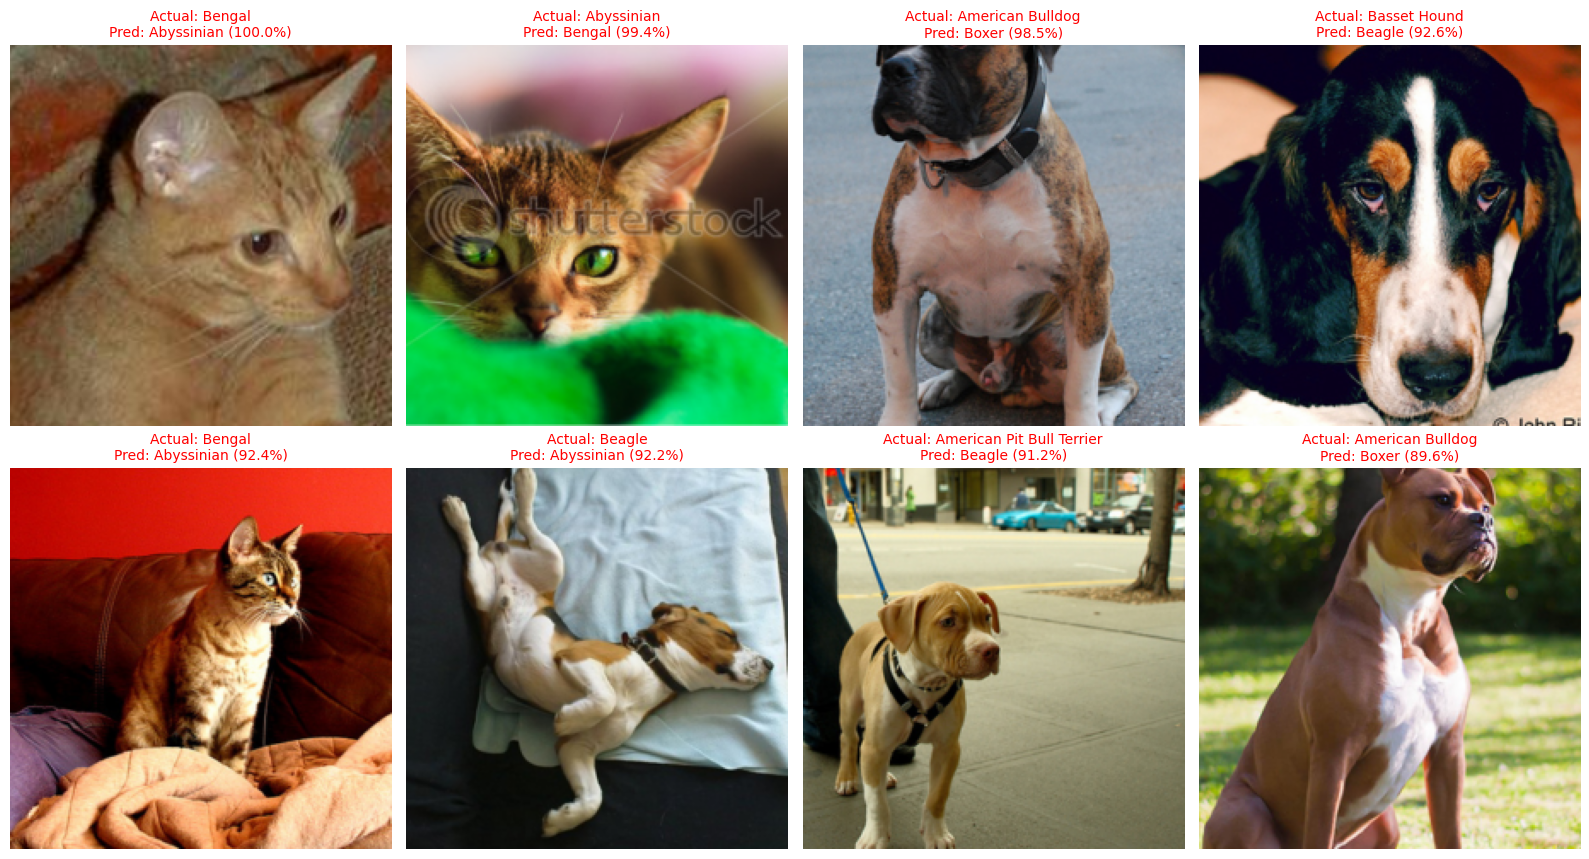

,ground_truth,prediction,confidence_pred,prob_true_class
0,Bengal,Abyssinian,1.0000,0.0000
1,Abyssinian,Bengal,0.9939,0.0053
2,American Bulldog,Boxer,0.9850,0.0138
3,Basset Hound,Beagle,0.9259,0.0659
4,Bengal,Abyssinian,0.9242,0.0199
5,Beagle,Abyssinian,0.9220,0.0748
6,American Pit Bull Terrier,Beagle,0.9120,0.0709
7,American Bulldog,Boxer,0.8964,0.0119


In [34]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

class_names = d1.classes[:10]

def show_failures(model, loader, n=8, save_path="failure_analysis.png"):
    model.eval()
    wrong = []
    with torch.no_grad():
        for x, y in loader:
            probs = F.softmax(model(x.to(device)), dim=1).cpu()
            conf, pred = probs.max(1)
            for k in range(len(y)):
                if pred[k] != y[k]:
                    wrong.append({
                        'image': x[k],
                        'true': y[k].item(),
                        'pred': pred[k].item(),
                        'conf': conf[k].item(),
                        'p_true': probs[k, y[k]].item()
                    })

    wrong = sorted(wrong, key=lambda d: -d["conf"])[:n]
    mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
    cols = 4
    rows = math.ceil(len(wrong) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4.4 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")

    table = []
    for ax, s in zip(axes, wrong):
        img = np.clip(s["image"].permute(1, 2, 0).numpy() * std + mean, 0, 1)
        ax.imshow(img)
        ax.set_title(f"Actual: {class_names[s['true']]}\nPred: {class_names[s['pred']]} ({s['conf']*100:.1f}%)", fontsize=10, color="red")
        table.append({
            'ground_truth': class_names[s["true"]],
            'prediction': class_names[s["pred"]],
            'confidence_pred': round(s["conf"], 4),
            'prob_true_class': round(s["p_true"], 4),
        })

    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()

    df = pd.DataFrame(table)
    df.to_csv("failure_cases.csv", index=False)
    return df

show_failures(best_model, test_loader, n=8)